# Noise and artefact correction

Generate an analytical TomoPhantom sample, simulate transmission counts and flat fields, normalise them, and compare FBP, PWLS-TV and SWLS-TV. This replaces the historical synthetic walkthrough with current code and newly executed figures.

Requires the [ToMoBAR CUDA environment](../getting_started/installation.rst), Matplotlib and **TomoPhantom**. Install TomoPhantom following its [installation guide](https://dkazanc.github.io/TomoPhantom/howto/installation.html) in the same environment. No data downloads are needed. Start with [regularised reconstruction](regularised_reconstruction.ipynb) for the simpler LS-TV comparison.

We retain model 16 from the original walkthrough, at size 64 instead of 256. The NumPy count simulator below makes the noise and calibration errors explicit and reproducible. It replaces the older flat-field simulator; retired wavelet and Group-Huber options are not used.

In [1]:
%matplotlib inline

from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
import subprocess

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import tomobar
import tomophantom
from tomophantom import TomoP3D

from tomobar.geometry import Parallel3DGeometry, Volume3DGeometry
from tomobar.options import DataFidelity, Regularisation
from tomobar.preprocessing import normaliser
from tomobar.reconstruction.direct import DirectReconstructor
from tomobar.reconstruction.iterative import IterativeReconstructor

print("Executed (UTC):", datetime.now(timezone.utc).isoformat(timespec="seconds"))
for package in ("tomobar", "numpy", "cupy", "astra-toolbox", "matplotlib"):
    print(f"{package}: {version(package)}")
source_root = Path(tomobar.__file__).resolve().parent.parent
if (source_root / ".git").exists():
    print(
        "Checkout revision:",
        subprocess.check_output(
            ["git", "-C", str(source_root), "rev-parse", "--short", "HEAD"], text=True
        ).strip(),
        "(local edits may be present)",
    )
device_index = 0
name = cp.cuda.runtime.getDeviceProperties(device_index)["name"]
print("GPU:", name.decode() if isinstance(name, bytes) else name)
print("CUDA runtime:", cp.cuda.runtime.runtimeGetVersion())


print("TomoPhantom:", version("tomophantom"))

Executed (UTC): 2026-11-18T22:16:03+00:00
tomobar: 2026.4.0.0
numpy: 2.4.6
cupy: 14.2.0
astra-toolbox: 2.5.0
matplotlib: 3.11.1
Checkout revision: d170474 (local edits may be present)
GPU: NVIDIA GeForce RTX 4060
CUDA runtime: 13020
TomoPhantom: 3.1.5.post0+git.fe04194d.dirty


## 1. Generate analytical projections

Model 16 contains both sharp and smooth structures. Its phantom is in `(z, y, x)` order and `ModelSino` returns `(detY, angles, detX)`. TomoPhantom takes angles in degrees; ToMoBAR takes radians. A common attenuation factor is applied to the phantom and its line integrals before simulating counts.

Analytical projection data are independent of the discrete ASTRA forward projector. Finite sampling and discretisation therefore contribute to reconstruction error, even before noise is added.

In [2]:
model, size, view_count = 16, 64, 100
attenuation_scale = 0.02
library = Path(tomophantom.__file__).parent / "phantomlib" / "Phantom3DLibrary.dat"
angles_deg = np.linspace(0, 180, view_count, endpoint=False, dtype=np.float32)
angles_rad = np.deg2rad(angles_deg)
detector_width = int(np.ceil(np.sqrt(2) * size))
phantom = attenuation_scale * TomoP3D.Model(model, size, str(library))
clean = attenuation_scale * TomoP3D.ModelSino(
    model, size, detector_width, size, angles_deg, str(library)
)
phantom = np.asarray(phantom, dtype=np.float32)
clean = np.asarray(clean, dtype=np.float32)
scan = Parallel3DGeometry.tomography(
    angles=angles_rad, detector_shape=(size, detector_width)
)
grid = Volume3DGeometry(shape=phantom.shape)
print("Phantom shape:", phantom.shape)
print("Projection shape (detY, angles, detX):", clean.shape)
print(f"Peak line integral: {clean.max():.4f}")

Phantom shape: (64, 64, 64)
Projection shape (detY, angles, detX): (64, 100, 91)
Peak line integral: 1.1518


## 2. Simulate raw counts and calibration errors

The incident flat field varies smoothly across the detector. Raw measurements contain Poisson noise and a dark offset. Three detector columns have a fixed gain error **absent from the calibration flats**, producing full-angle stripes after normalisation. The defect is intentionally simple so SWLS can be inspected; real detector errors may vary with angle and time.

The count level is 15,000, as in the original example. We generate 20 calibration flats and 20 darks. The negative logarithm restores line integrals directly; no phantom-dependent rescaling is applied after reconstruction.

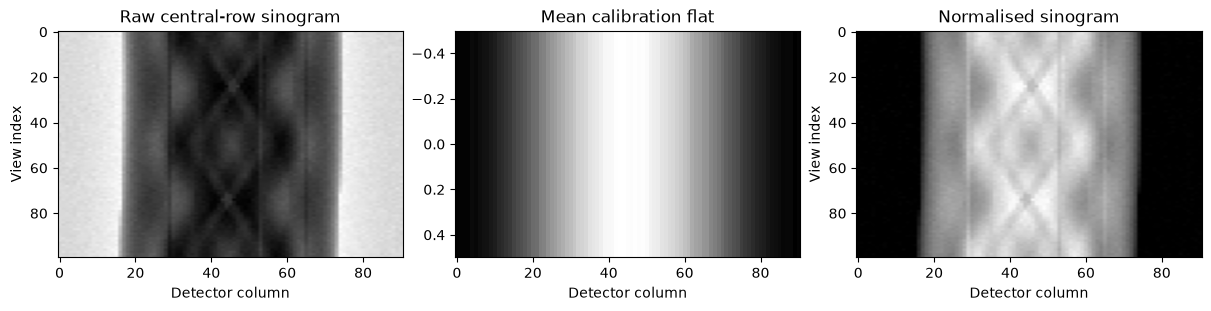

In [3]:
rng = np.random.default_rng(42)
incident_counts, dark_offset, calibration_frames = 15000, 100, 20
columns = np.linspace(-1, 1, detector_width, dtype=np.float32)
incident = np.broadcast_to(
    incident_counts * (0.85 + 0.1 * np.cos(np.pi * columns)), (size, detector_width)
)
gain = np.ones((size, detector_width), dtype=np.float32)
for column, response in (
    (detector_width // 2 - 16, 0.92),
    (detector_width // 2 + 8, 1.08),
    (detector_width // 2 + 20, 0.94),
):
    gain[:, column] = response
raw = rng.poisson(
    incident[:, None, :] * gain[:, None, :] * np.exp(-clean) + dark_offset
).astype(np.float32)
flats = rng.poisson(
    np.broadcast_to(
        incident[:, None, :] + dark_offset, (size, calibration_frames, detector_width)
    )
).astype(np.float32)
darks = rng.poisson(dark_offset, (size, calibration_frames, detector_width)).astype(
    np.float32
)
projections = np.asarray(
    normaliser(raw, flats, darks, log=True, method="mean", axis=1), dtype=np.float32
)
assert np.isfinite(projections).all()

figure, axes = plt.subplots(1, 3, figsize=(12, 3), constrained_layout=True)
for axis, image, title in zip(
    axes,
    (raw[size // 2], flats[size // 2].mean(axis=0)[None, :], projections[size // 2]),
    ("Raw central-row sinogram", "Mean calibration flat", "Normalised sinogram"),
):
    axis.imshow(image, cmap="gray", aspect="auto")
    axis.set_title(title)
    axis.set_xlabel("Detector column")
axes[0].set_ylabel("View index")
axes[2].set_ylabel("View index")
plt.show()

## 3. Reconstruct with FBP and TV-regularised FISTA

PWLS uses raw counts as approximate inverse-variance weights. The solver normalises these weights by their maximum. SWLS adds a stripe correction controlled by `beta_swls`; it can reduce full-angle stripes but is not a general correction for every ring artefact.

Both iterative runs use the same PD-TV strength and 30 outer iterations with four interleaved subsets. Each outer iteration visits every subset. These are illustrative settings, not guaranteed optimal parameters. TV favours piecewise-constant regions and can smooth the model's Gaussian structures. The original strength values are not reused because the current solver scaling and data size differ.

In [4]:
images = {}
with DirectReconstructor(
    projection_geometry=scan, volume_geometry=grid, device_index=device_index
) as rec:
    images["FBP"] = cp.asnumpy(
        rec.FBP(projections, filter_type="RAM-LAK", recon_mask_radius=None)
    )

with IterativeReconstructor(
    projection_geometry=scan,
    volume_geometry=grid,
    num_subsets=4,
    device_index=device_index,
) as rec:
    lipschitz = rec.powermethod()
    tv = Regularisation(method="PD_TV", strength=0.02, iterations=50)
    for method in ("PWLS", "SWLS"):
        images[f"{method}-TV"] = cp.asnumpy(
            rec.FISTA(
                projections,
                fidelity=DataFidelity(method=method, beta_swls=1.0),
                weights=raw,
                regularisation=tv,
                iterations=30,
                lipschitz_constant=lipschitz,
                nonnegativity=True,
                recon_mask_radius=None,
            )
        )

for label, image in images.items():
    print(
        f"{label:10s} full-volume RMSE: {np.sqrt(np.mean((image - phantom) ** 2)):.5f}"
    )

FBP        full-volume RMSE: 0.00226
PWLS-TV    full-volume RMSE: 0.00215
SWLS-TV    full-volume RMSE: 0.00174


## 4. Inspect noise, rings and smooth features

The upper row shares an intensity range; the lower row shares an absolute-error range. Compare rings around the sample centre, noise in uniform regions and the smooth structures. RMSE uses the full unmasked volume and includes analytical/discrete-projector differences. A single scalar does not describe every artefact.

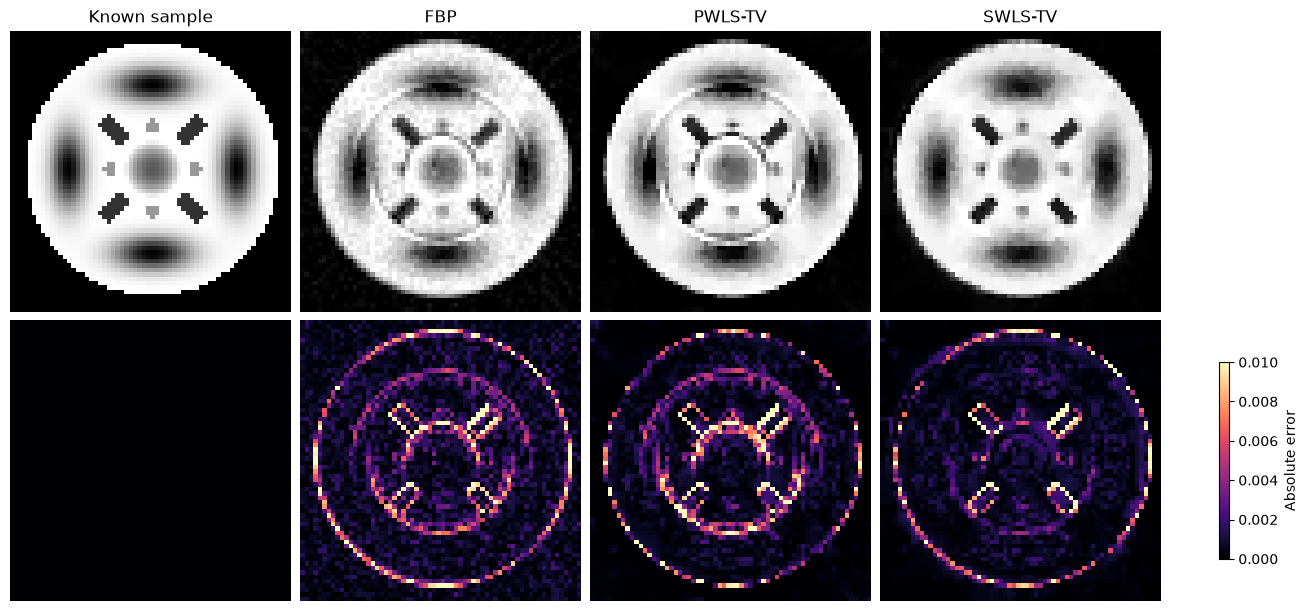

In [5]:
comparison = {"Known sample": phantom, **images}
figure, axes = plt.subplots(2, 4, figsize=(13, 6), constrained_layout=True)
for column, (label, image) in enumerate(comparison.items()):
    axes[0, column].imshow(
        image[size // 2], cmap="gray", vmin=0, vmax=phantom.max(), origin="lower"
    )
    axes[0, column].set_title(label)
    errors = axes[1, column].imshow(
        np.abs(image - phantom)[size // 2],
        cmap="magma",
        vmin=0,
        vmax=0.01,
        origin="lower",
    )
    for axis in axes[:, column]:
        axis.set_axis_off()
figure.colorbar(errors, ax=axes[1, :], shrink=0.7, label="Absolute error")
plt.show()

## Next steps

Change the gain error, photon count, TV strength or SWLS parameter and rerun the comparison. Partial-angle stripes need a richer model than the fixed detector errors simulated here.

Continue with [experimental dendrite tomography](experimental_dendrites.ipynb), or consult [data preparation](../howto/prepare_projections.rst), [regularisation](../howto/regularisation.rst) and [solver settings](../howto/configure_solvers.rst). The larger standalone source example remains `demos/synthetic/tomophantom_3d_artifacts.py`.